# CS3807 – Deep Learning Laboratory | Experiment 7
## End-to-End Study of Autoencoders, Convolutional Autoencoders, Denoising Autoencoders and Variational Autoencoders

**Dataset:** MNIST (10,000 train / 2,000 test subset) &nbsp;|&nbsp; **Framework:** TensorFlow / Keras

**Runtime:** Runtime → Change runtime type → **T4 GPU** (optional, but faster). Then *Runtime → Run all*.

**Contents**
1. Setup & data
2. Fully connected AE (Plots 1, 2 + metrics)
3. Convolutional AE (Plot 3 + comparison)
4. Denoising CAE (Plots 4, 5)
5. Variational AE (Plots 6, 7, 8, VAE loss curves)
6. Reconstruction-error distribution & high-error images
7. Latent-dimension study (Plot 10)
8. Consolidated results
9. Inferences & discussion answers (write from your own results)

## 1. Setup and Data

In [ ]:
import time, random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from skimage.metrics import structural_similarity as ssim_fn

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
print("TensorFlow:", tf.__version__, "| Keras:", keras.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.20.0 | Keras: 3.13.2
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
# ---- Load MNIST, normalise to [0,1], take the recommended lab subset ----
(x_tr_full, y_tr_full), (x_te_full, y_te_full) = keras.datasets.mnist.load_data()

N_TRAIN, N_TEST = 10000, 2000
x_train_all = (x_tr_full[:N_TRAIN].astype("float32") / 255.0)[..., None]   # (10000,28,28,1)
y_train_all = y_tr_full[:N_TRAIN]
x_test      = (x_te_full[:N_TEST].astype("float32") / 255.0)[..., None]    # (2000,28,28,1)
y_test      = y_te_full[:N_TEST]

# Hold out 10% of the training subset for validation (test set stays unseen during training)
n_val = int(0.1 * N_TRAIN)
x_train, x_val = x_train_all[:-n_val], x_train_all[-n_val:]
y_train, y_val = y_train_all[:-n_val], y_train_all[-n_val:]

print("train:", x_train.shape, "| val:", x_val.shape, "| test:", x_test.shape)
print("pixel range:", x_train.min(), "to", x_train.max())

train: (9000, 28, 28, 1) | val: (1000, 28, 28, 1) | test: (2000, 28, 28, 1)
pixel range: 0.0 to 1.0


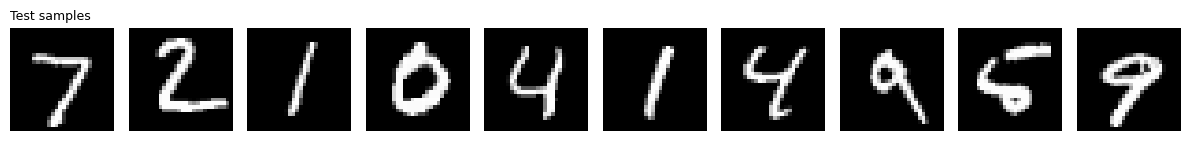

Labels: [7 2 1 0 4 1 4 9 5 9]


In [ ]:
# ---- Shared helpers ----
results = {}   # consolidated results table: name -> dict(MSE, MAE, SSIM, Params, Time)

def evaluate_recon(x, xh):
    """Global MSE, MAE and mean SSIM between originals x and reconstructions xh (N,28,28,1)."""
    mse = float(np.mean((x - xh) ** 2))
    mae = float(np.mean(np.abs(x - xh)))
    ss  = float(np.mean([ssim_fn(x[i, :, :, 0], xh[i, :, :, 0], data_range=1.0) for i in range(len(x))]))
    return mse, mae, ss

def per_image_mse(x, xh):
    """e_i = (1/D) * sum_j (x_ij - xhat_ij)^2"""
    return np.mean((x - xh) ** 2, axis=(1, 2, 3))

def show_rows(rows, row_titles, n=10, figsize=None, suptitle=None):
    """rows: list of arrays (N,28,28,1). Displays first n images of each row."""
    fig, axes = plt.subplots(len(rows), n, figsize=figsize or (1.2 * n, 1.35 * len(rows)))
    axes = np.atleast_2d(axes)
    for r, (arr, title) in enumerate(zip(rows, row_titles)):
        for c in range(n):
            axes[r, c].imshow(arr[c, :, :, 0], cmap="gray", vmin=0, vmax=1)
            axes[r, c].axis("off")
        axes[r, 0].set_title(title, fontsize=9, loc="left")
    if suptitle: fig.suptitle(suptitle, y=1.02)
    plt.tight_layout(); plt.show()

def plot_history(hist, title, ylabel="Reconstruction loss"):
    plt.figure(figsize=(6, 4))
    plt.plot(hist.history["loss"], label="Training loss")
    plt.plot(hist.history["val_loss"], label="Validation loss")
    plt.xlabel("Epoch"); plt.ylabel(ylabel); plt.title(title)
    plt.legend(); plt.grid(alpha=0.3); plt.show()

def print_table(rows, header):
    widths = [max(len(str(h)), *(len(f"{r[i]:.5f}" if isinstance(r[i], float) else str(r[i])) for r in rows)) for i, h in enumerate(header)]
    line = " | ".join(str(h).ljust(w) for h, w in zip(header, widths)); print(line); print("-" * len(line))
    for r in rows:
        print(" | ".join((f"{v:.5f}" if isinstance(v, float) else str(v)).ljust(w) for v, w in zip(r, widths)))

# quick look at the data
show_rows([x_test[:10]], ["Test samples"], n=10, figsize=(12, 1.6))
print("Labels:", y_test[:10])

## 2. Fully Connected Autoencoder

Architecture: `784 → 128 → 32 → z → 32 → 128 → 784` (ReLU hidden, sigmoid output).  
Adam (lr = 1e-3), batch 128, 20 epochs, binary cross-entropy.

In [ ]:
def build_fc_ae(latent_dim=16):
    inp = keras.Input(shape=(784,))
    h = layers.Dense(128, activation="relu")(inp)
    h = layers.Dense(32, activation="relu")(h)
    z = layers.Dense(latent_dim, name="latent")(h)            # linear latent code
    h = layers.Dense(32, activation="relu")(z)
    h = layers.Dense(128, activation="relu")(h)
    out = layers.Dense(784, activation="sigmoid")(h)
    m = keras.Model(inp, out, name=f"FC_AE_z{latent_dim}")
    m.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy")
    return m

def flat(x): return x.reshape(len(x), -1)
def unflat(x): return x.reshape(-1, 28, 28, 1)

fc_ae = build_fc_ae(16)
fc_ae.summary()

t0 = time.time()
hist_fc = fc_ae.fit(flat(x_train), flat(x_train), epochs=20, batch_size=128,
                    validation_data=(flat(x_val), flat(x_val)), verbose=2)
t_fc = time.time() - t0
print(f"Training time: {t_fc:.1f}s")

Model: "FC_AE_z16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_10 (InputLayer)     │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_27 (Dense)                │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_28 (Dense)                │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent (Dense)                  │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_29 (Dense)                │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_30 (Dense)                │ (None, 128)            │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_31 (Dense)                │ (None, 784)            │       101,136 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 211,040 (824.38 KB)

 Trainable params: 211,040 (824.38 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
71/71 - 4s - 59ms/step - loss: 0.3516 - val_loss: 0.2606
Epoch 2/20
71/71 - 0s - 4ms/step - loss: 0.2299 - val_loss: 0.2075
Epoch 3/20
71/71 - 0s - 4ms/step - loss: 0.1924 - val_loss: 0.1845
Epoch 4/20
71/71 - 0s - 4ms/step - loss: 0.1720 - val_loss: 0.1697
Epoch 5/20
71/71 - 0s - 4ms/step - loss: 0.1612 - val_loss: 0.1615
Epoch 6/20
71/71 - 0s - 4ms/step - loss: 0.1529 - val_loss: 0.1545
Epoch 7/20
71/71 - 0s - 4ms/step - loss: 0.1460 - val_loss: 0.1488
Epoch 8/20
71/71 - 0s - 4ms/step - loss: 0.1410 - val_loss: 0.1448
Epoch 9/20
71/71 - 0s - 4ms/step - loss: 0.1375 - val_loss: 0.1420
Epoch 10/20
71/71 - 0s - 4ms/step - loss: 0.1348 - val_loss: 0.1398
Epoch 11/20
71/71 - 0s - 4ms/step - loss: 0.1326 - val_loss: 0.1380
Epoch 12/20
71/71 - 0s - 4ms/step - loss: 0.1308 - val_loss: 0.1365
Epoch 13/20
71/71 - 0s - 4ms/step - loss: 0.1292 - val_loss: 0.1350
Epoch 14/20
71/71 - 0s - 4ms/step - loss: 0.1275 - val_loss: 0.1335
Epoch 15/20
71/71 - 0s - 4ms/step - loss: 0.1259 - val_l

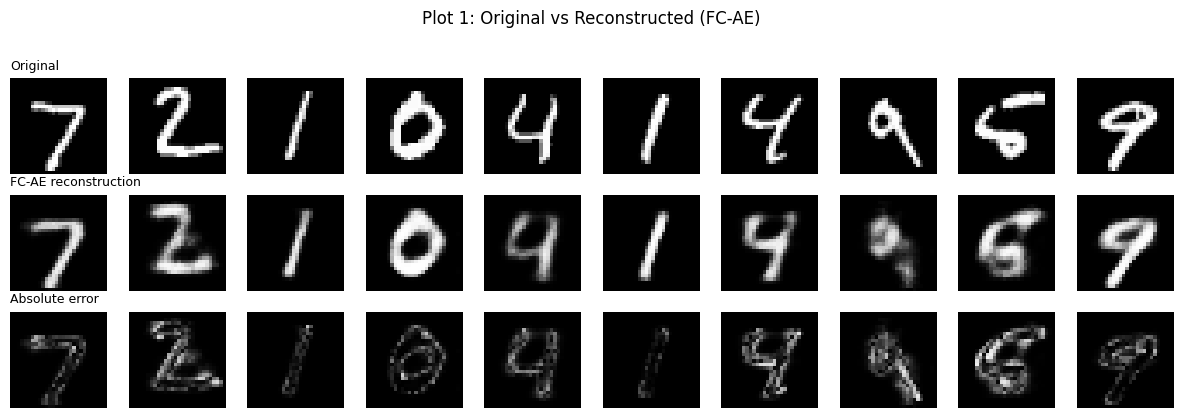

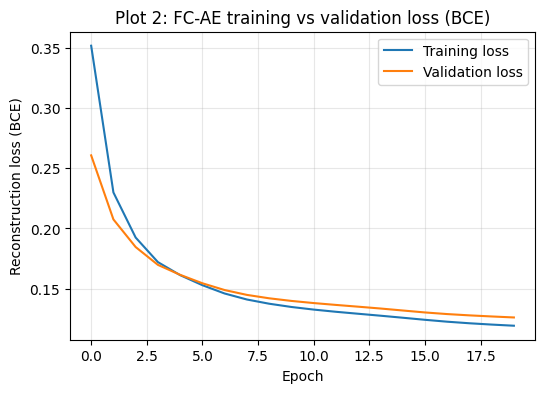

Metric    | Value  
-------------------
Test MSE  | 0.02046
Test MAE  | 0.05512
Mean SSIM | 0.75861
Final train loss: 0.1192 | Final val loss: 0.1261 | gap: 0.0069


In [ ]:
# ---- Plot 1: original vs reconstruction (FC-AE) ----
xh_fc = unflat(fc_ae.predict(flat(x_test), verbose=0))
show_rows([x_test[:10], xh_fc[:10], np.abs(x_test[:10] - xh_fc[:10])],
          ["Original", "FC-AE reconstruction", "Absolute error"], suptitle="Plot 1: Original vs Reconstructed (FC-AE)")

# ---- Plot 2: training / validation loss ----
plot_history(hist_fc, "Plot 2: FC-AE training vs validation loss (BCE)", "Reconstruction loss (BCE)")

# ---- Test metrics ----
mse, mae, ss = evaluate_recon(x_test, xh_fc)
results["FC Autoencoder"] = dict(MSE=mse, MAE=mae, SSIM=ss, Params=fc_ae.count_params(), Time=t_fc)
print_table([["Test MSE", mse], ["Test MAE", mae], ["Mean SSIM", ss]], ["Metric", "Value"])
print("Final train loss: %.4f | Final val loss: %.4f | gap: %.4f" %
      (hist_fc.history["loss"][-1], hist_fc.history["val_loss"][-1],
       hist_fc.history["val_loss"][-1] - hist_fc.history["loss"][-1]))

## 3. Convolutional Autoencoder (CAE)
Same data, same optimizer / batch size / epochs for a controlled comparison.

Model: "CAE"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_11 (InputLayer)     │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_18 (Conv2D)              │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent (MaxPooling2D)           │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_19 (Conv2D)              │ (None, 7, 7, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_6 (UpSampling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_20 (Conv2D)              │ (None, 14, 14, 32)     │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_7 (UpSampling2D)  │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_21 (Conv2D)              │ (None, 28, 28, 1)      │           289 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 74,497 (291.00 KB)

 Trainable params: 74,497 (291.00 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
71/71 - 6s - 80ms/step - loss: 0.2618 - val_loss: 0.1141
Epoch 2/20
71/71 - 1s - 8ms/step - loss: 0.0958 - val_loss: 0.0903
Epoch 3/20
71/71 - 1s - 8ms/step - loss: 0.0848 - val_loss: 0.0839
Epoch 4/20
71/71 - 1s - 8ms/step - loss: 0.0803 - val_loss: 0.0801
Epoch 5/20
71/71 - 1s - 8ms/step - loss: 0.0774 - val_loss: 0.0776
Epoch 6/20
71/71 - 1s - 8ms/step - loss: 0.0755 - val_loss: 0.0762
Epoch 7/20
71/71 - 1s - 7ms/step - loss: 0.0741 - val_loss: 0.0752
Epoch 8/20
71/71 - 1s - 8ms/step - loss: 0.0731 - val_loss: 0.0742
Epoch 9/20
71/71 - 1s - 7ms/step - loss: 0.0723 - val_loss: 0.0735
Epoch 10/20
71/71 - 1s - 8ms/step - loss: 0.0717 - val_loss: 0.0729
Epoch 11/20
71/71 - 1s - 9ms/step - loss: 0.0711 - val_loss: 0.0723
Epoch 12/20
71/71 - 1s - 9ms/step - loss: 0.0707 - val_loss: 0.0718
Epoch 13/20
71/71 - 1s - 9ms/step - loss: 0.0703 - val_loss: 0.0713
Epoch 14/20
71/71 - 1s - 8ms/step - loss: 0.0699 - val_loss: 0.0710
Epoch 15/20
71/71 - 1s - 8ms/step - loss: 0.0696 - val_l

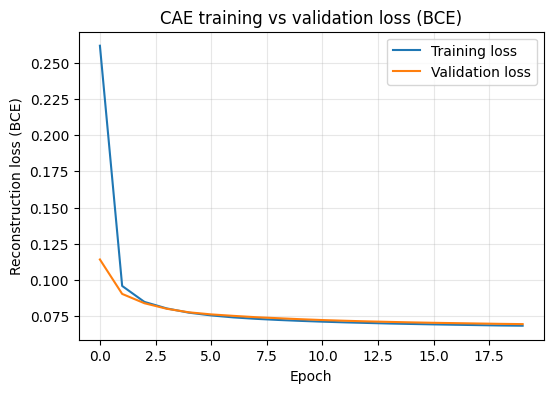

In [ ]:
def build_cae():
    inp = keras.Input(shape=(28, 28, 1))
    x = layers.Conv2D(32, 3, activation="relu", padding="same")(inp)
    x = layers.MaxPooling2D(2, padding="same")(x)                       # 14x14
    x = layers.Conv2D(64, 3, activation="relu", padding="same")(x)
    x = layers.MaxPooling2D(2, padding="same", name="latent")(x)        # 7x7x64 latent feature map
    x = layers.Conv2D(64, 3, activation="relu", padding="same")(x)
    x = layers.UpSampling2D(2)(x)                                       # 14x14
    x = layers.Conv2D(32, 3, activation="relu", padding="same")(x)
    x = layers.UpSampling2D(2)(x)                                       # 28x28
    out = layers.Conv2D(1, 3, activation="sigmoid", padding="same")(x)
    m = keras.Model(inp, out, name="CAE")
    m.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy")
    return m

cae = build_cae()
cae.summary()

t0 = time.time()
hist_cae = cae.fit(x_train, x_train, epochs=20, batch_size=128,
                   validation_data=(x_val, x_val), verbose=2)
t_cae = time.time() - t0
print(f"Training time: {t_cae:.1f}s")

xh_cae = cae.predict(x_test, verbose=0)
mse, mae, ss = evaluate_recon(x_test, xh_cae)
results["Conv. Autoencoder"] = dict(MSE=mse, MAE=mae, SSIM=ss, Params=cae.count_params(), Time=t_cae)
plot_history(hist_cae, "CAE training vs validation loss (BCE)", "Reconstruction loss (BCE)")

Model             | MSE     | MAE     | SSIM    | Parameters
------------------------------------------------------------
FC Autoencoder    | 0.02046 | 0.05512 | 0.75861 | 211040    
Conv. Autoencoder | 0.00261 | 0.01499 | 0.97408 | 74497     


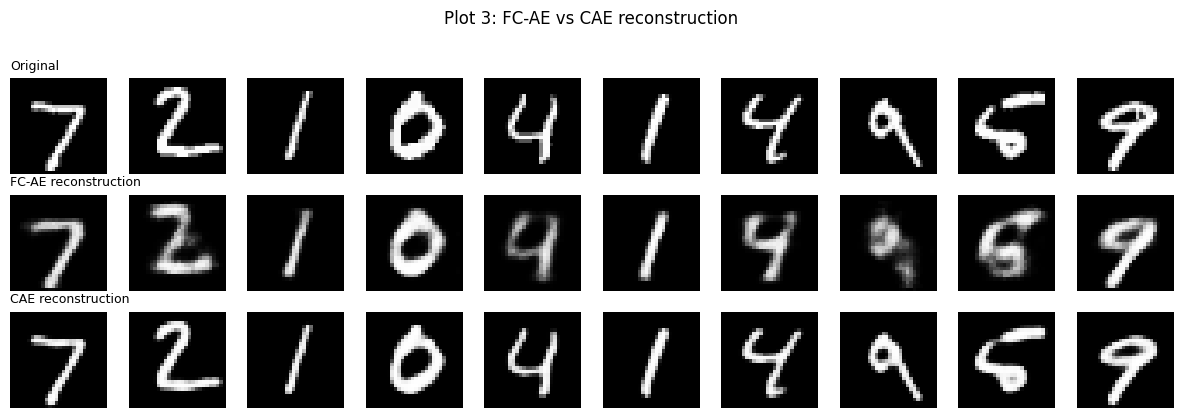

In [ ]:
# ---- Comparison table + Plot 3 ----
print_table([[k, v["MSE"], v["MAE"], v["SSIM"], v["Params"]] for k, v in results.items()
             if k in ("FC Autoencoder", "Conv. Autoencoder")],
            ["Model", "MSE", "MAE", "SSIM", "Parameters"])

show_rows([x_test[:10], xh_fc[:10], xh_cae[:10]],
          ["Original", "FC-AE reconstruction", "CAE reconstruction"],
          suptitle="Plot 3: FC-AE vs CAE reconstruction")

## 4. Denoising Convolutional Autoencoder
Input = noisy image, **target = clean image**.  
Two corruptions: Gaussian (σ ∈ {0.1, 0.2, 0.3}) and salt-and-pepper (p ∈ {0.05, 0.10, 0.20}).  
Each model is trained at one mid-level noise (σ = 0.2 / p = 0.10) and evaluated across all levels.

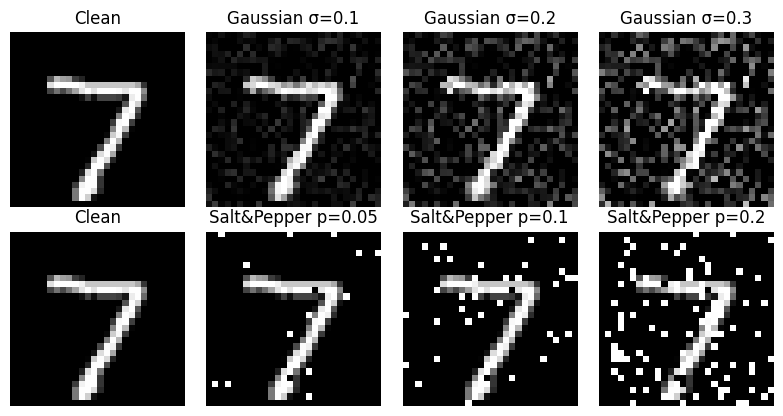

In [ ]:
def add_gaussian(x, sigma, seed=0):
    rng = np.random.default_rng(seed)
    return np.clip(x + rng.normal(0.0, sigma, x.shape).astype("float32"), 0.0, 1.0)

def add_salt_pepper(x, p, seed=0):
    rng = np.random.default_rng(seed)
    r = rng.random(x.shape)
    out = x.copy()
    out[r < p / 2] = 0.0                    # pepper
    out[(r >= p / 2) & (r < p)] = 1.0       # salt
    return out

# Preview the noise levels
fig, axes = plt.subplots(2, 4, figsize=(8, 4.2))
axes[0, 0].imshow(x_test[0, :, :, 0], cmap="gray"); axes[0, 0].set_title("Clean")
axes[1, 0].imshow(x_test[0, :, :, 0], cmap="gray"); axes[1, 0].set_title("Clean")
for j, s in enumerate([0.1, 0.2, 0.3]):
    axes[0, j + 1].imshow(add_gaussian(x_test[:1], s)[0, :, :, 0], cmap="gray", vmin=0, vmax=1); axes[0, j + 1].set_title(f"Gaussian σ={s}")
for j, p in enumerate([0.05, 0.10, 0.20]):
    axes[1, j + 1].imshow(add_salt_pepper(x_test[:1], p)[0, :, :, 0], cmap="gray", vmin=0, vmax=1); axes[1, j + 1].set_title(f"Salt&Pepper p={p}")
for a in axes.ravel(): a.axis("off")
plt.tight_layout(); plt.show()

Epoch 1/20
71/71 - 7s - 92ms/step - loss: 0.2648 - val_loss: 0.1276
Epoch 2/20
71/71 - 1s - 9ms/step - loss: 0.1099 - val_loss: 0.1022
Epoch 3/20
71/71 - 1s - 8ms/step - loss: 0.0954 - val_loss: 0.0939
Epoch 4/20
71/71 - 1s - 8ms/step - loss: 0.0900 - val_loss: 0.0902
Epoch 5/20
71/71 - 1s - 8ms/step - loss: 0.0868 - val_loss: 0.0875
Epoch 6/20
71/71 - 1s - 8ms/step - loss: 0.0849 - val_loss: 0.0859
Epoch 7/20
71/71 - 1s - 8ms/step - loss: 0.0830 - val_loss: 0.0840
Epoch 8/20
71/71 - 1s - 8ms/step - loss: 0.0818 - val_loss: 0.0830
Epoch 9/20
71/71 - 1s - 8ms/step - loss: 0.0808 - val_loss: 0.0820
Epoch 10/20
71/71 - 1s - 8ms/step - loss: 0.0800 - val_loss: 0.0812
Epoch 11/20
71/71 - 1s - 8ms/step - loss: 0.0793 - val_loss: 0.0808
Epoch 12/20
71/71 - 1s - 8ms/step - loss: 0.0787 - val_loss: 0.0801
Epoch 13/20
71/71 - 1s - 8ms/step - loss: 0.0782 - val_loss: 0.0797
Epoch 14/20
71/71 - 1s - 8ms/step - loss: 0.0778 - val_loss: 0.0792
Epoch 15/20
71/71 - 1s - 8ms/step - loss: 0.0774 - val_l

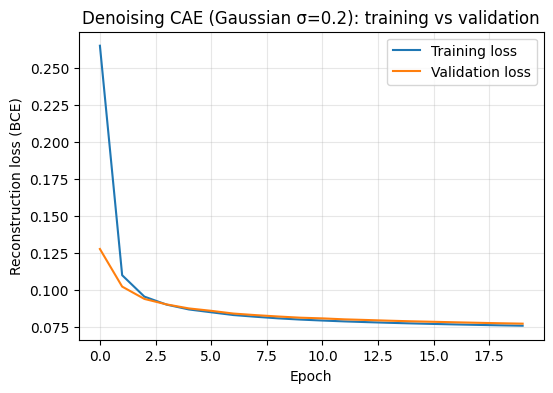

Gaussian noise (model trained at sigma=0.2)
Noise σ | MSE     | MAE     | SSIM    | Noisy MSE | Noisy MAE | Noisy SSIM
--------------------------------------------------------------------------
0.10000 | 0.00378 | 0.01822 | 0.95818 | 0.00544   | 0.04408   | 0.67878   
0.20000 | 0.00479 | 0.02170 | 0.94325 | 0.02123   | 0.08663   | 0.59355   
0.30000 | 0.00726 | 0.02974 | 0.87095 | 0.04667   | 0.12806   | 0.50894   


In [ ]:
# ---- Train Gaussian-denoising CAE (sigma = 0.2) ----
SIG_TRAIN = 0.2
xn_train = add_gaussian(x_train, SIG_TRAIN, seed=1)
xn_val   = add_gaussian(x_val,   SIG_TRAIN, seed=2)

dcae_g = build_cae()
t0 = time.time()
hist_dg = dcae_g.fit(xn_train, x_train, epochs=20, batch_size=128,
                     validation_data=(xn_val, x_val), verbose=2)
t_dg = time.time() - t0
plot_history(hist_dg, "Denoising CAE (Gaussian σ=0.2): training vs validation", "Reconstruction loss (BCE)")

# ---- Evaluate over noise levels (Plot 5 data) ----
gauss_levels = [0.1, 0.2, 0.3]
rows_g = []
for s in gauss_levels:
    xn = add_gaussian(x_test, s, seed=100)
    xd = dcae_g.predict(xn, verbose=0)
    m_noisy = evaluate_recon(x_test, xn)      # baseline: noisy vs clean
    m_den   = evaluate_recon(x_test, xd)      # denoised vs clean
    rows_g.append([s, *m_den, *m_noisy])
print("Gaussian noise (model trained at sigma=0.2)")
print_table(rows_g, ["Noise σ", "MSE", "MAE", "SSIM", "Noisy MSE", "Noisy MAE", "Noisy SSIM"])

results["Denoising CAE"] = dict(MSE=rows_g[1][1], MAE=rows_g[1][2], SSIM=rows_g[1][3],
                                Params=dcae_g.count_params(), Time=t_dg)   # reported at sigma=0.2

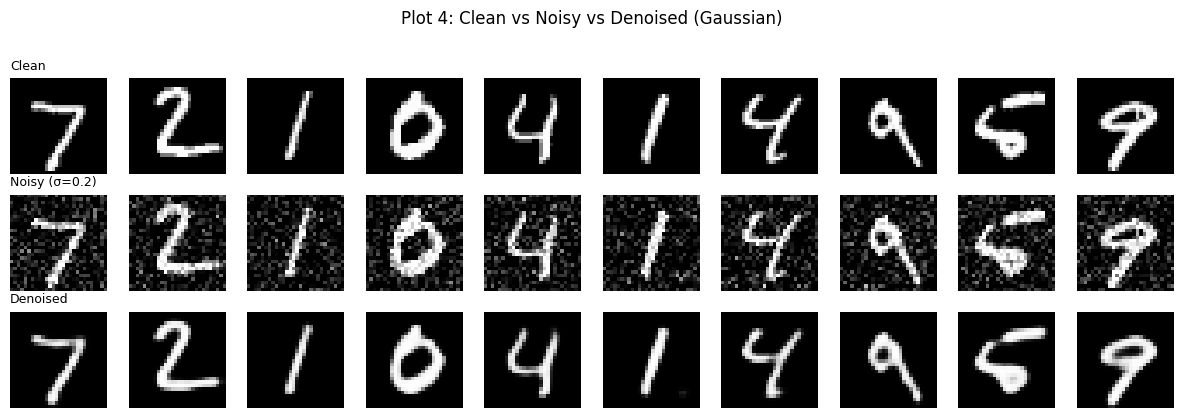

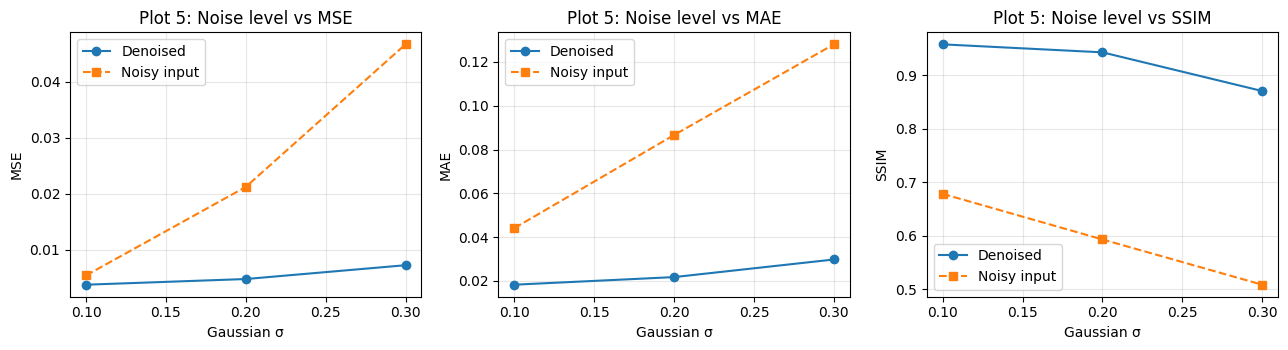

In [ ]:
# ---- Plot 4: clean vs noisy vs denoised (Gaussian σ=0.2) ----
xn_test = add_gaussian(x_test, 0.2, seed=100)
xd_test = dcae_g.predict(xn_test, verbose=0)
show_rows([x_test[:10], xn_test[:10], xd_test[:10]], ["Clean", "Noisy (σ=0.2)", "Denoised"],
          suptitle="Plot 4: Clean vs Noisy vs Denoised (Gaussian)")

# ---- Plot 5: noise level vs quality (separate figures for incompatible scales) ----
arr = np.array(rows_g)
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
for a, (name, idx, nidx) in zip(ax, [("MSE", 1, 4), ("MAE", 2, 5), ("SSIM", 3, 6)]):
    a.plot(arr[:, 0], arr[:, idx], "o-", label="Denoised")
    a.plot(arr[:, 0], arr[:, nidx], "s--", label="Noisy input")
    a.set_xlabel("Gaussian σ"); a.set_ylabel(name); a.set_title(f"Plot 5: Noise level vs {name}")
    a.grid(alpha=0.3); a.legend()
plt.tight_layout(); plt.show()

Salt-and-pepper noise (model trained at p=0.10)
Corruption p | MSE     | MAE     | SSIM    | Noisy MSE | Noisy MAE | Noisy SSIM
-------------------------------------------------------------------------------
0.05000      | 0.00418 | 0.01914 | 0.95599 | 0.02404   | 0.02496   | 0.70922   
0.10000      | 0.00506 | 0.02141 | 0.94332 | 0.04820   | 0.05002   | 0.57805   
0.20000      | 0.00814 | 0.02888 | 0.88753 | 0.09636   | 0.10002   | 0.44683   


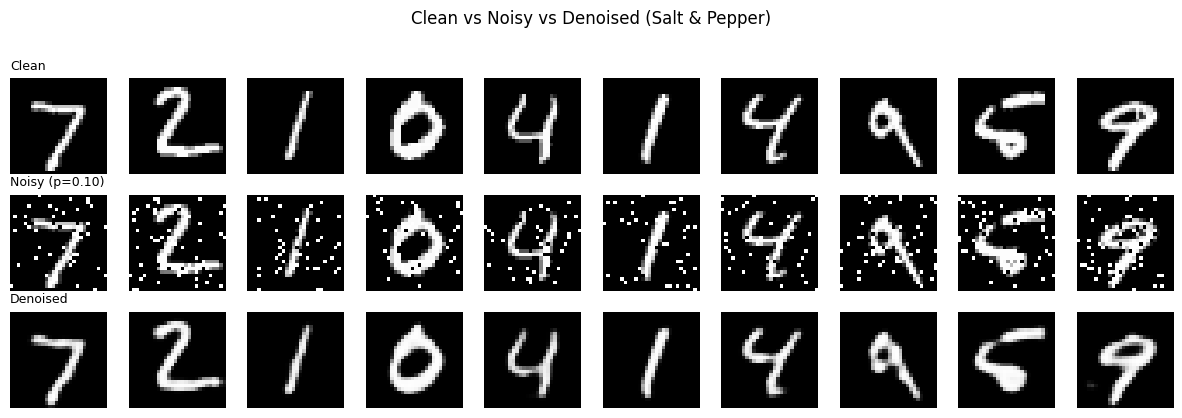

In [ ]:
# ---- Salt-and-pepper denoising CAE (p = 0.10) ----
P_TRAIN = 0.10
dcae_sp = build_cae()
t0 = time.time()
hist_dsp = dcae_sp.fit(add_salt_pepper(x_train, P_TRAIN, seed=3), x_train, epochs=20, batch_size=128,
                       validation_data=(add_salt_pepper(x_val, P_TRAIN, seed=4), x_val), verbose=0)
t_dsp = time.time() - t0

rows_sp = []
for p in [0.05, 0.10, 0.20]:
    xn = add_salt_pepper(x_test, p, seed=200)
    xd = dcae_sp.predict(xn, verbose=0)
    rows_sp.append([p, *evaluate_recon(x_test, xd), *evaluate_recon(x_test, xn)])
print("Salt-and-pepper noise (model trained at p=0.10)")
print_table(rows_sp, ["Corruption p", "MSE", "MAE", "SSIM", "Noisy MSE", "Noisy MAE", "Noisy SSIM"])

xn_sp = add_salt_pepper(x_test, 0.10, seed=200)
show_rows([x_test[:10], xn_sp[:10], dcae_sp.predict(xn_sp[:10], verbose=0)],
          ["Clean", "Noisy (p=0.10)", "Denoised"], suptitle="Clean vs Noisy vs Denoised (Salt & Pepper)")

## 5. Variational Autoencoder (latent dimension = 2)
Encoder → (μ, log σ²) → reparameterisation `z = μ + σ ⊙ ε` → decoder.  
Loss = reconstruction (BCE summed over pixels) + KL divergence to N(0, I), both averaged per image.

In [ ]:
LATENT = 2

class Sampling(layers.Layer):
    """Reparameterisation trick: z = mu + sigma * eps,  eps ~ N(0, I)."""
    def call(self, inputs):
        mu, logvar = inputs
        eps = tf.random.normal(tf.shape(mu))
        return mu + tf.exp(0.5 * logvar) * eps

def build_vae_encoder(latent_dim=LATENT):
    inp = keras.Input(shape=(28, 28, 1))
    x = layers.Conv2D(32, 3, strides=2, padding="same", activation="relu")(inp)   # 14x14
    x = layers.Conv2D(64, 3, strides=2, padding="same", activation="relu")(x)     # 7x7
    x = layers.Flatten()(x)
    x = layers.Dense(128, activation="relu")(x)
    mu = layers.Dense(latent_dim, name="mu")(x)
    logvar = layers.Dense(latent_dim, name="log_var")(x)
    z = Sampling(name="z")([mu, logvar])
    return keras.Model(inp, [mu, logvar, z], name="vae_encoder")

def build_vae_decoder(latent_dim=LATENT):
    inp = keras.Input(shape=(latent_dim,))
    x = layers.Dense(7 * 7 * 64, activation="relu")(inp)
    x = layers.Reshape((7, 7, 64))(x)
    x = layers.Conv2DTranspose(64, 3, strides=2, padding="same", activation="relu")(x)   # 14x14
    x = layers.Conv2DTranspose(32, 3, strides=2, padding="same", activation="relu")(x)   # 28x28
    out = layers.Conv2DTranspose(1, 3, padding="same", activation="sigmoid")(x)
    return keras.Model(inp, out, name="vae_decoder")

class VAE(keras.Model):
    def __init__(self, encoder, decoder, kl_weight=1.0, **kwargs):
        super().__init__(**kwargs)
        self.encoder, self.decoder, self.kl_weight = encoder, decoder, kl_weight
        self.total_tracker = keras.metrics.Mean(name="loss")
        self.rec_tracker   = keras.metrics.Mean(name="rec_loss")
        self.kl_tracker    = keras.metrics.Mean(name="kl_loss")

    @property
    def metrics(self):
        return [self.total_tracker, self.rec_tracker, self.kl_tracker]

    def _compute_losses(self, x):
        mu, logvar, z = self.encoder(x, training=True)
        xh = self.decoder(z, training=True)
        # BCE per pixel -> sum over the 28x28 pixels -> mean over the batch
        rec = tf.reduce_mean(tf.reduce_sum(keras.losses.binary_crossentropy(x, xh), axis=(1, 2)))
        # KL(q(z|x) || N(0,I)) = -1/2 sum(1 + log s^2 - mu^2 - s^2), mean over batch
        kl = tf.reduce_mean(-0.5 * tf.reduce_sum(1.0 + logvar - tf.square(mu) - tf.exp(logvar), axis=1))
        return rec, kl

    def _update(self, rec, kl):
        total = rec + self.kl_weight * kl
        self.total_tracker.update_state(total)
        self.rec_tracker.update_state(rec)
        self.kl_tracker.update_state(kl)
        return total

    def train_step(self, data):
        x = data[0] if isinstance(data, (tuple, list)) else data
        with tf.GradientTape() as tape:
            rec, kl = self._compute_losses(x)
            total = rec + self.kl_weight * kl
        grads = tape.gradient(total, self.trainable_weights)
        self.optimizer.apply_gradients(zip(grads, self.trainable_weights))
        self._update(rec, kl)
        return {m.name: m.result() for m in self.metrics}

    def test_step(self, data):
        x = data[0] if isinstance(data, (tuple, list)) else data
        rec, kl = self._compute_losses(x)
        self._update(rec, kl)
        return {m.name: m.result() for m in self.metrics}

encoder = build_vae_encoder(); decoder = build_vae_decoder()
encoder.summary(); decoder.summary()

vae = VAE(encoder, decoder, kl_weight=1.0)
vae.compile(optimizer=keras.optimizers.Adam(1e-3))

t0 = time.time()
hist_vae = vae.fit(x_train, x_train, epochs=30, batch_size=128,
                   validation_data=(x_val, x_val), verbose=2)
t_vae = time.time() - t0
print(f"Training time: {t_vae:.1f}s")

Model: "vae_encoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_14      │ (None, 28, 28, 1) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_32 (Conv2D)  │ (None, 14, 14,    │        320 │ input_layer_14[0… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_33 (Conv2D)  │ (None, 7, 7, 64)  │     18,496 │ conv2d_32[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_1 (Flatten) │ (None, 3136)      │          0 │ conv2d_33[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_32 (Dense)    │ (None, 128)       │    401,536 │ flatten_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mu (Dense)          │ (None, 2)         │        258 │ dense_32[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ log_var (Dense)     │ (None, 2)         │        258 │ dense_32[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z (Sampling)        │ (None, 2)         │          0 │ mu[0][0],         │
│                     │                   │            │ log_var[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 420,868 (1.61 MB)

 Trainable params: 420,868 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_15 (InputLayer)     │ (None, 2)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_33 (Dense)                │ (None, 3136)           │         9,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_1 (Reshape)             │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_3              │ (None, 14, 14, 64)     │        36,928 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_4              │ (None, 28, 28, 32)     │        18,464 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_5              │ (None, 28, 28, 1)      │           289 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 65,089 (254.25 KB)

 Trainable params: 65,089 (254.25 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
71/71 - 9s - 121ms/step - kl_loss: 4.8919 - loss: 294.9612 - rec_loss: 290.0694 - val_kl_loss: 3.5184 - val_loss: 208.7172 - val_rec_loss: 205.1988
Epoch 2/30
71/71 - 1s - 11ms/step - kl_loss: 3.0860 - loss: 199.4253 - rec_loss: 196.3393 - val_kl_loss: 2.8393 - val_loss: 196.6813 - val_rec_loss: 193.8420
Epoch 3/30
71/71 - 1s - 9ms/step - kl_loss: 3.5661 - loss: 189.2452 - rec_loss: 185.6791 - val_kl_loss: 4.1399 - val_loss: 186.0716 - val_rec_loss: 181.9316
Epoch 4/30
71/71 - 1s - 10ms/step - kl_loss: 4.1473 - loss: 182.4611 - rec_loss: 178.3138 - val_kl_loss: 4.2303 - val_loss: 183.2075 - val_rec_loss: 178.9772
Epoch 5/30
71/71 - 1s - 15ms/step - kl_loss: 4.2491 - loss: 179.5542 - rec_loss: 175.3051 - val_kl_loss: 4.1838 - val_loss: 179.7540 - val_rec_loss: 175.5702
Epoch 6/30
71/71 - 1s - 7ms/step - kl_loss: 4.3263 - loss: 176.2474 - rec_loss: 171.9211 - val_kl_loss: 4.2376 - val_loss: 175.3774 - val_rec_loss: 171.1398
Epoch 7/30
71/71 - 1s - 7ms/step - kl_loss: 4.5548 - 

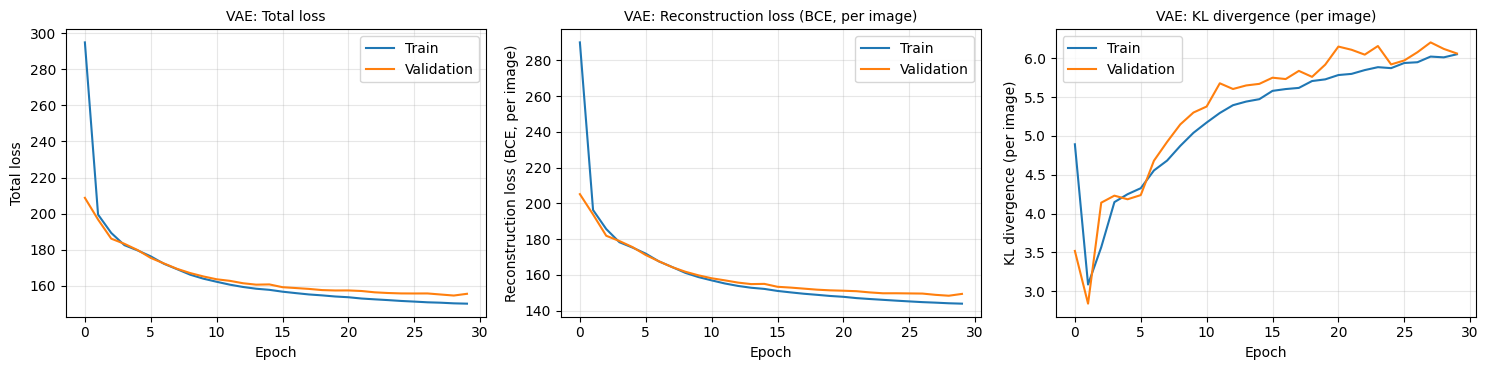

VAE metric                    | Value    
-----------------------------------------
Reconstruction loss (BCE/img) | 148.19533
KL loss                       | 5.93679  
Total loss                    | 154.13214
Test MSE                      | 0.04300  
Test MAE                      | 0.10105  
Mean SSIM                     | 0.49774  


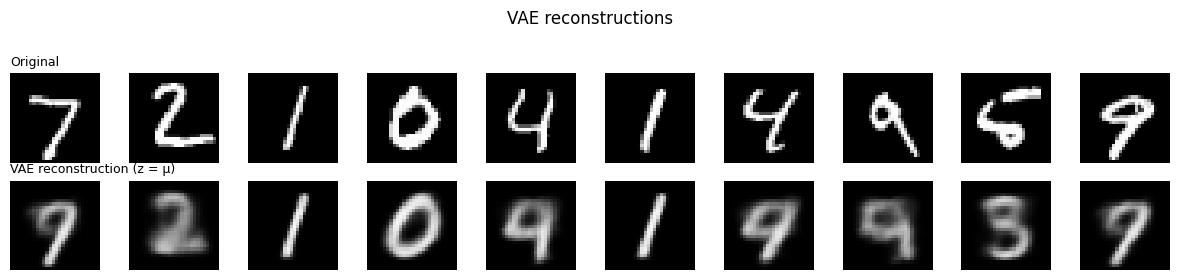

In [ ]:
# ---- VAE training / validation curves (total, reconstruction, KL) ----
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for a, (k, title) in zip(ax, [("loss", "Total loss"), ("rec_loss", "Reconstruction loss (BCE, per image)"), ("kl_loss", "KL divergence (per image)")]):
    a.plot(hist_vae.history[k], label="Train"); a.plot(hist_vae.history["val_" + k], label="Validation")
    a.set_xlabel("Epoch"); a.set_ylabel(title); a.set_title("VAE: " + title, fontsize=10); a.grid(alpha=0.3); a.legend()
plt.tight_layout(); plt.show()

# ---- VAE test losses and reconstruction metrics (deterministic decode of z = mu) ----
te = vae.evaluate(x_test, x_test, batch_size=128, verbose=0, return_dict=True)
mu_te, logvar_te, _ = encoder.predict(x_test, verbose=0)
xh_vae = decoder.predict(mu_te, verbose=0)
mse, mae, ss = evaluate_recon(x_test, xh_vae)
vae_params = encoder.count_params() + decoder.count_params()
results["VAE"] = dict(MSE=mse, MAE=mae, SSIM=ss, Params=vae_params, Time=t_vae)

print_table([["Reconstruction loss (BCE/img)", te["rec_loss"]], ["KL loss", te["kl_loss"]], ["Total loss", te["loss"]],
             ["Test MSE", mse], ["Test MAE", mae], ["Mean SSIM", ss]], ["VAE metric", "Value"])

show_rows([x_test[:10], xh_vae[:10]], ["Original", "VAE reconstruction (z = μ)"], suptitle="VAE reconstructions")

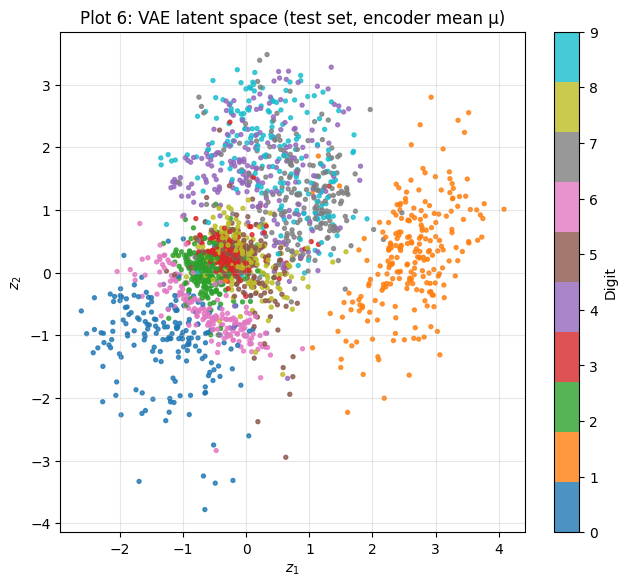

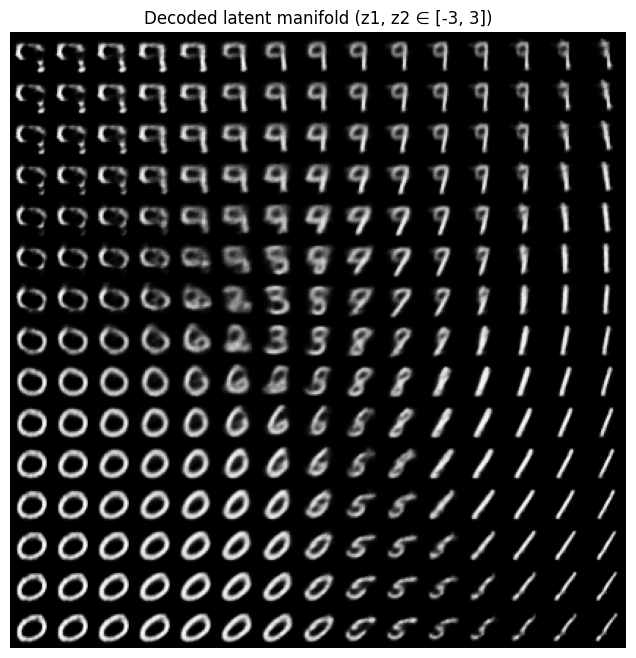

In [ ]:
# ---- Plot 6: 2-D latent space coloured by digit (labels used ONLY for colouring) ----
plt.figure(figsize=(7.5, 6.5))
sc = plt.scatter(mu_te[:, 0], mu_te[:, 1], c=y_test, cmap="tab10", s=8, alpha=0.8)
plt.colorbar(sc, ticks=range(10), label="Digit")
plt.xlabel("$z_1$"); plt.ylabel("$z_2$"); plt.title("Plot 6: VAE latent space (test set, encoder mean μ)")
plt.grid(alpha=0.3); plt.show()

# Extra: decoded manifold over a regular grid of the latent plane
n, span = 15, 3.0
grid_x = np.linspace(-span, span, n); grid_y = np.linspace(span, -span, n)
canvas = np.zeros((28 * n, 28 * n))
for i, yi in enumerate(grid_y):
    for j, xj in enumerate(grid_x):
        canvas[i*28:(i+1)*28, j*28:(j+1)*28] = decoder.predict(np.array([[xj, yi]]), verbose=0)[0, :, :, 0]
plt.figure(figsize=(8, 8)); plt.imshow(canvas, cmap="gray"); plt.axis("off")
plt.title("Decoded latent manifold (z1, z2 ∈ [-3, 3])"); plt.show()

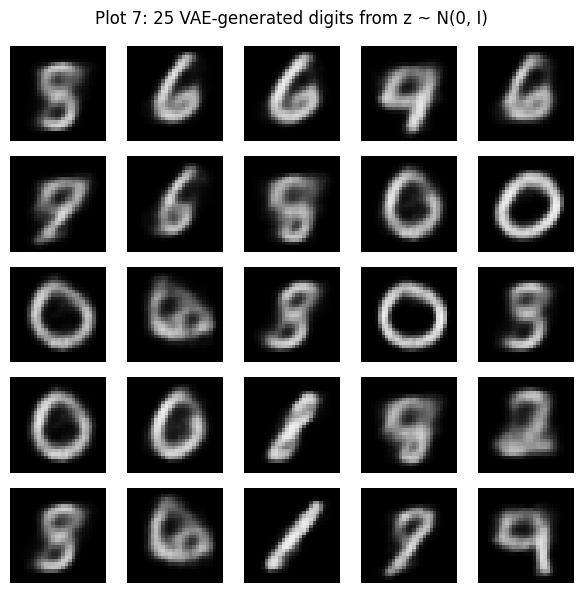

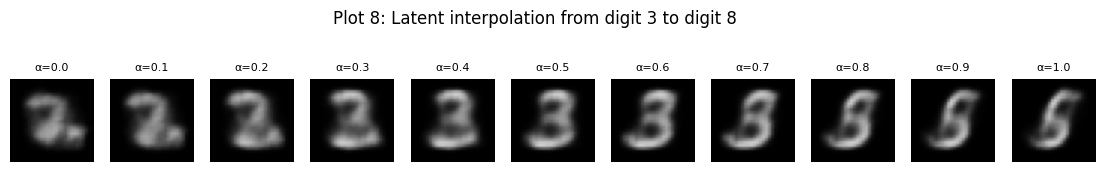

In [ ]:
# ---- Plot 7: randomly generated images (z ~ N(0, I)) ----
rng = np.random.default_rng(7)
z_rand = rng.standard_normal((25, LATENT)).astype("float32")
gen = decoder.predict(z_rand, verbose=0)

fig, axes = plt.subplots(5, 5, figsize=(6, 6))
for i, a in enumerate(axes.ravel()):
    a.imshow(gen[i, :, :, 0], cmap="gray", vmin=0, vmax=1); a.axis("off")
fig.suptitle("Plot 7: 25 VAE-generated digits from z ~ N(0, I)"); plt.tight_layout(); plt.show()

# ---- Plot 8: latent-space interpolation between two test images of different digits ----
def find_idx(d): return int(np.where(y_test == d)[0][0])
dA, dB = 3, 8                                 # change digits to explore other regions
zA, zB = mu_te[find_idx(dA)], mu_te[find_idx(dB)]
alphas = np.linspace(0, 1, 11)
z_interp = np.stack([(1 - a) * zA + a * zB for a in alphas]).astype("float32")
dec_interp = decoder.predict(z_interp, verbose=0)

fig, axes = plt.subplots(1, 11, figsize=(14, 1.9))
for a, ax, img in zip(alphas, axes, dec_interp):
    ax.imshow(img[:, :, 0], cmap="gray", vmin=0, vmax=1); ax.axis("off"); ax.set_title(f"α={a:.1f}", fontsize=8)
fig.suptitle(f"Plot 8: Latent interpolation from digit {dA} to digit {dB}", y=1.08); plt.show()

## 6. Reconstruction-Error Distribution and High-Error Images

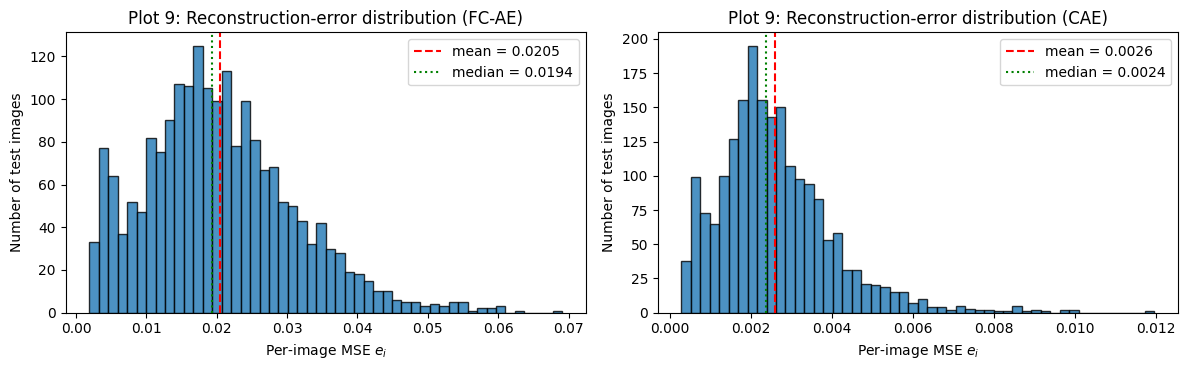

FC-AE: min=0.00188  median=0.01936  mean=0.02046  95th pct=0.03947  max=0.06910
CAE: min=0.00029  median=0.00238  mean=0.00261  95th pct=0.00522  max=0.01196


In [ ]:
# ---- Plot 9: per-image reconstruction-error histogram (CAE + FC-AE) ----
err_cae = per_image_mse(x_test, xh_cae)
err_fc  = per_image_mse(x_test, xh_fc)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for a, err, name in zip(ax, [err_fc, err_cae], ["FC-AE", "CAE"]):
    a.hist(err, bins=50, edgecolor="black", alpha=0.8)
    a.axvline(err.mean(), color="r", ls="--", label=f"mean = {err.mean():.4f}")
    a.axvline(np.median(err), color="g", ls=":", label=f"median = {np.median(err):.4f}")
    a.set_xlabel("Per-image MSE $e_i$"); a.set_ylabel("Number of test images")
    a.set_title(f"Plot 9: Reconstruction-error distribution ({name})"); a.legend()
plt.tight_layout(); plt.show()
for name, err in [("FC-AE", err_fc), ("CAE", err_cae)]:
    print(f"{name}: min={err.min():.5f}  median={np.median(err):.5f}  mean={err.mean():.5f}  "
          f"95th pct={np.percentile(err, 95):.5f}  max={err.max():.5f}")

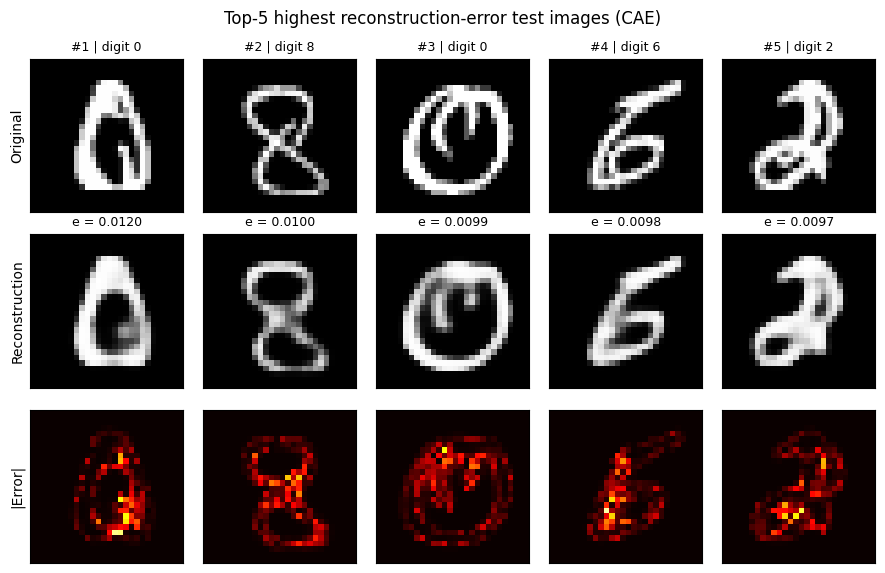

Sample | Test index | Digit | Error  
-------------------------------------
1      | 895        | 0     | 0.01196
2      | 431        | 8     | 0.01003
3      | 1526       | 0     | 0.00991
4      | 1982       | 6     | 0.00977
5      | 1395       | 2     | 0.00974


In [ ]:
# ---- Five highest-error test images (CAE) ----
top5 = np.argsort(err_cae)[-5:][::-1]
fig, axes = plt.subplots(3, 5, figsize=(9, 5.8))
for c, idx in enumerate(top5):
    axes[0, c].imshow(x_test[idx, :, :, 0], cmap="gray", vmin=0, vmax=1);   axes[0, c].set_title(f"#{c+1} | digit {y_test[idx]}", fontsize=9)
    axes[1, c].imshow(xh_cae[idx, :, :, 0], cmap="gray", vmin=0, vmax=1);   axes[1, c].set_title(f"e = {err_cae[idx]:.4f}", fontsize=9)
    axes[2, c].imshow(np.abs(x_test[idx, :, :, 0] - xh_cae[idx, :, :, 0]), cmap="hot", vmin=0, vmax=1)
axes[0, 0].set_ylabel("Original"); axes[1, 0].set_ylabel("Reconstruction"); axes[2, 0].set_ylabel("|Error|")
for a in axes.ravel(): a.set_xticks([]); a.set_yticks([])
plt.suptitle("Top-5 highest reconstruction-error test images (CAE)"); plt.tight_layout(); plt.show()
print_table([[i + 1, int(idx), int(y_test[idx]), float(err_cae[idx])] for i, idx in enumerate(top5)],
            ["Sample", "Test index", "Digit", "Error"])

## 7. Additional Study: Latent Dimension of the Basic AE
Repeat the FC autoencoder with `d_z ∈ {2, 8, 16, 32}`.

Latent dim | MSE     | SSIM    | Parameters
-------------------------------------------
2          | 0.04584 | 0.45156 | 210130    
8          | 0.02648 | 0.68857 | 210520    
16         | 0.02292 | 0.72648 | 211040    
32         | 0.02111 | 0.75005 | 212080    


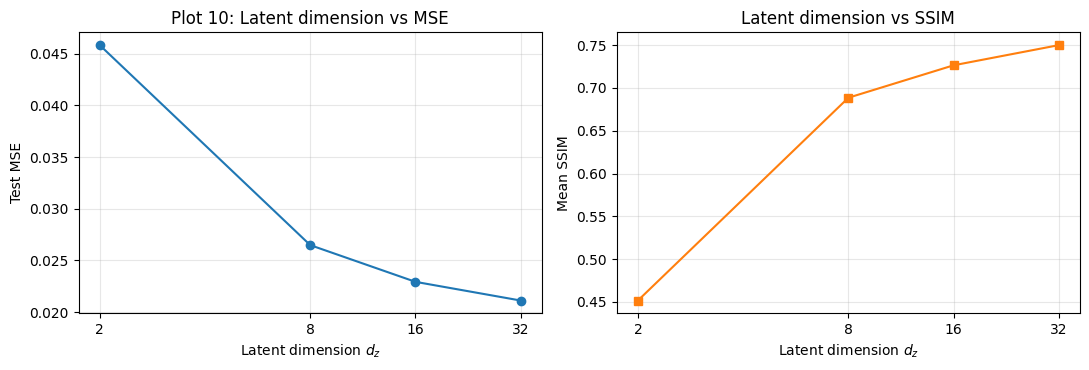

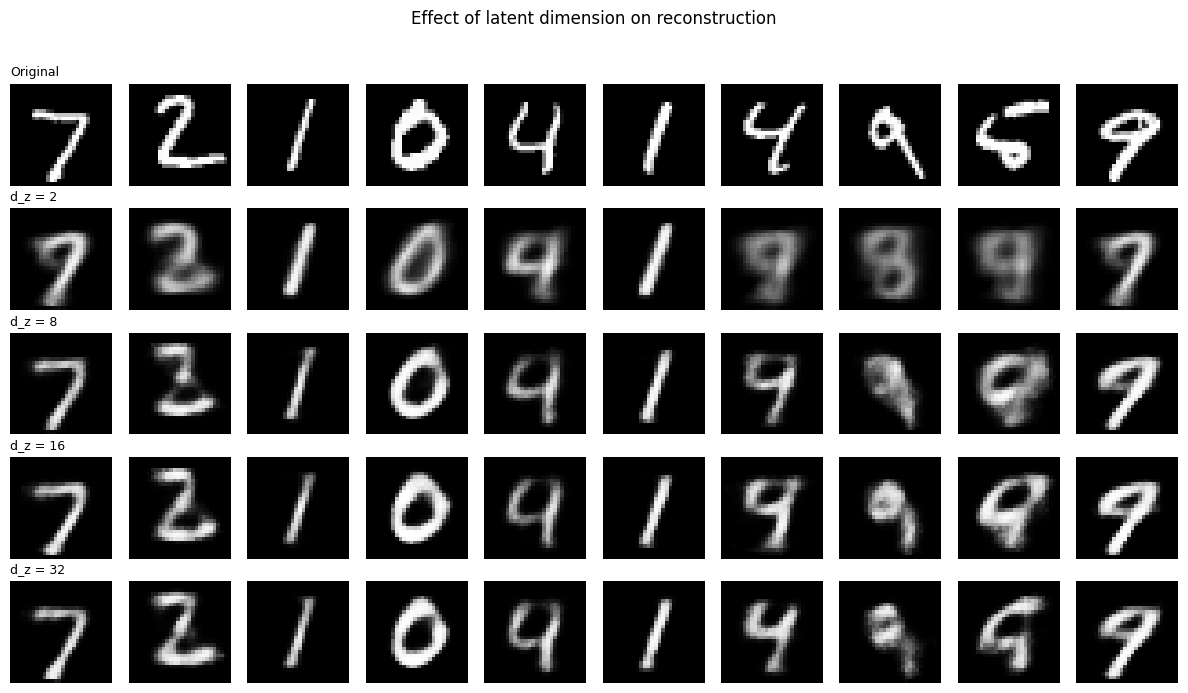

In [ ]:
dims = [2, 8, 16, 32]
dz_rows, dz_models = [], {}
for d in dims:
    m = build_fc_ae(d)
    m.fit(flat(x_train), flat(x_train), epochs=20, batch_size=128,
          validation_data=(flat(x_val), flat(x_val)), verbose=0)
    xh = unflat(m.predict(flat(x_test), verbose=0))
    mse, mae, ss = evaluate_recon(x_test, xh)
    dz_rows.append([d, mse, ss, m.count_params()]); dz_models[d] = xh
print_table(dz_rows, ["Latent dim", "MSE", "SSIM", "Parameters"])

# ---- Plot 10: latent dimension vs MSE (and SSIM on a separate figure) ----
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot([r[0] for r in dz_rows], [r[1] for r in dz_rows], "o-"); ax[0].set_xscale("log", base=2)
ax[0].set_xticks(dims); ax[0].set_xticklabels(dims)
ax[0].set_xlabel("Latent dimension $d_z$"); ax[0].set_ylabel("Test MSE"); ax[0].set_title("Plot 10: Latent dimension vs MSE"); ax[0].grid(alpha=0.3)
ax[1].plot([r[0] for r in dz_rows], [r[2] for r in dz_rows], "s-", color="tab:orange"); ax[1].set_xscale("log", base=2)
ax[1].set_xticks(dims); ax[1].set_xticklabels(dims)
ax[1].set_xlabel("Latent dimension $d_z$"); ax[1].set_ylabel("Mean SSIM"); ax[1].set_title("Latent dimension vs SSIM"); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

show_rows([x_test[:10]] + [dz_models[d][:10] for d in dims], ["Original"] + [f"d_z = {d}" for d in dims],
          suptitle="Effect of latent dimension on reconstruction")

## 8. Consolidated Results

Model             | MSE     | MAE     | SSIM    | Parameters | Time (s)
-----------------------------------------------------------------------
FC Autoencoder    | 0.02046 | 0.05512 | 0.75861 | 211040     | 9.70000 
Conv. Autoencoder | 0.00261 | 0.01499 | 0.97408 | 74497      | 16.60000
Denoising CAE     | 0.00479 | 0.02170 | 0.94325 | 74497      | 17.10000
VAE               | 0.04300 | 0.10105 | 0.49774 | 485957     | 26.00000

Notes: Denoising CAE is evaluated on Gaussian-noisy test images (σ = 0.2) vs the clean originals.
       VAE metrics use the deterministic reconstruction z = μ; its losses are reported separately above.


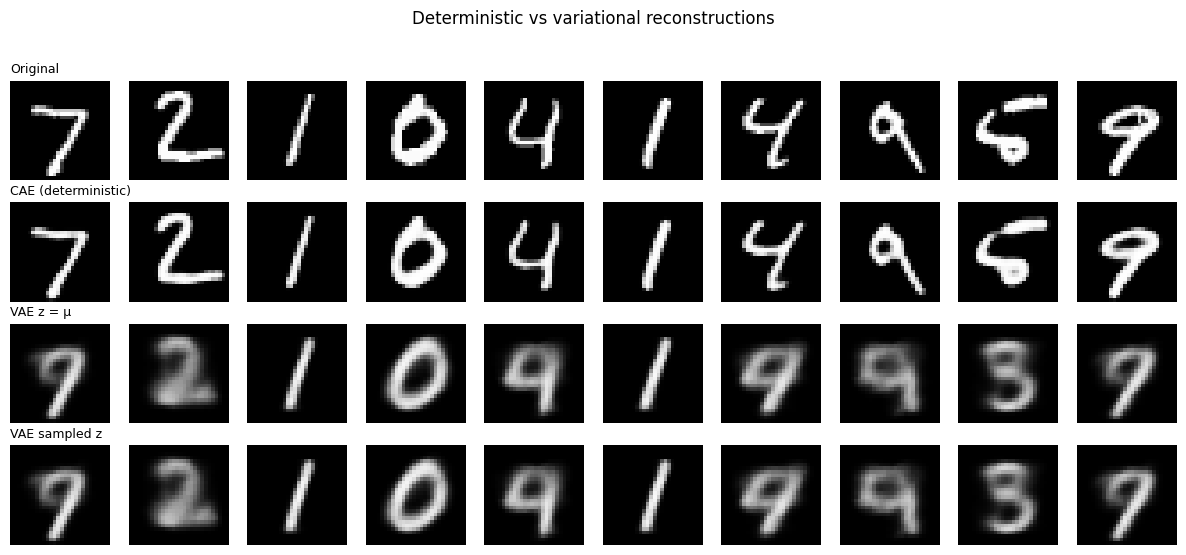

In [ ]:
order = ["FC Autoencoder", "Conv. Autoencoder", "Denoising CAE", "VAE"]
print_table([[k, results[k]["MSE"], results[k]["MAE"], results[k]["SSIM"], results[k]["Params"], round(results[k]["Time"], 1)] for k in order],
            ["Model", "MSE", "MAE", "SSIM", "Parameters", "Time (s)"])
print("\nNotes: Denoising CAE is evaluated on Gaussian-noisy test images (σ = 0.2) vs the clean originals.")
print("       VAE metrics use the deterministic reconstruction z = μ; its losses are reported separately above.")

# Deterministic vs probabilistic reconstruction side by side
xh_vae_sample = decoder.predict(encoder.predict(x_test[:10], verbose=0)[2], verbose=0)
show_rows([x_test[:10], xh_cae[:10], xh_vae[:10], xh_vae_sample],
          ["Original", "CAE (deterministic)", "VAE z = μ", "VAE sampled z"], suptitle="Deterministic vs variational reconstructions")

## 9. Inferences (fill in from *your own* run)

For each plot answer: **(1) what it shows, (2) the trend, (3) why it occurs, (4) the conclusion.**  
The numbers change between runs, so write these after your final execution. Prompts below tell you what to look at.

| # | Mandatory inference | Look at |
|---|---|---|
| 1 | Effect of latent dimension | Plot 10 table: MSE/SSIM vs d_z; d_z = 2 blur vs d_z = 32 sharpness; diminishing returns |
| 2 | FC vs convolutional | Plot 3 + comparison table: parameters vs SSIM, stroke continuity, local structure |
| 3 | Effect of Gaussian noise | Plot 5: MSE/MAE rise, SSIM falls as σ grows; compare denoised vs noisy-input curves |
| 4 | Denoising ability | Plot 4: are digit identity & strokes recovered? Which details are lost (thin strokes, heavy noise)? |
| 5 | VAE latent distribution | KL value; how the cloud in Plot 6 is centred near 0 with roughly unit spread |
| 6 | 2-D latent structure | Plot 6 + manifold: clusters per digit, overlap between 4/9, 3/5/8, 7/9 |
| 7 | Generated sample quality/diversity | Plot 7: recognisable digits? blurry / ambiguous ones? variety of classes? |
| 8 | Interpolation smoothness | Plot 8: gradual morph vs abrupt jumps; intermediate "in-between" digits |
| 9 | Error vs visual quality | Plot 9 + top-5 images: unusual writing styles, thick/thin/slanted strokes, ambiguous digits |
| 10 | Deterministic vs probabilistic latent | AE vs VAE: reconstruction sharpness, generative ability, regularised latent space |

**Training-curve check (Plot 2):** converged if the loss flattens; overfitting if validation loss rises/flattens while training loss keeps falling.

## 10. Discussion Questions – Short Answer Key (verify against your results)

1. **Autoencoder** – a neural network trained to reproduce its input through a bottleneck: x → encoder → z → decoder → x̂.
2. **Encoder** – compresses the input into a lower-dimensional latent code z = f_θ(x).
3. **Decoder** – reconstructs the input from z: x̂ = g_φ(z).
4. **Latent representation** – the compact code in the bottleneck holding the information needed for reconstruction.
5. **Why smaller than input** – forces the network to learn salient structure instead of copying (identity mapping).
6. **Latent too small** – information bottleneck is too tight: blurry reconstructions, digits merge, high MSE.
7. **Latent increased** – better reconstruction but less compression, and risk of near-identity mapping / weaker features.
8. **Why CAE preserves spatial information** – shared local filters and pooling/upsampling exploit 2-D locality with far fewer parameters; flattening in FC layers discards neighbourhood structure.
9. **AE vs DAE** – an AE reconstructs its own input; a DAE receives a corrupted input and reconstructs the clean one.
10. **Clean target in denoising** – so the model learns to remove noise and recover the underlying signal, not to reproduce the corruption.
11. **Higher noise** – MSE/MAE increase, SSIM decreases, fine strokes are lost; recovery becomes ambiguous.
12. **MSE, MAE, SSIM** – MSE penalises large errors, MAE is robust average error, SSIM measures perceptual structure (luminance, contrast, structure) that pixel errors miss.
13. **VAE** – a generative autoencoder whose encoder outputs a distribution q_φ(z|x) regularised toward a prior.
14. **VAE vs AE** – stochastic latent (μ, σ) with KL regularisation vs deterministic code with reconstruction loss only.
15. **Distribution vs single vector** – gives a continuous, smooth latent space that can be sampled; neighbouring points decode to similar images.
16. **Reparameterisation trick** – z = μ + σ ⊙ ε moves the randomness into ε so gradients flow through μ and σ.
17. **ε ~ N(0, I)** – a fixed, simple, parameter-free noise source that matches the prior's scale and keeps the sampling differentiable.
18. **KL role** – pulls q(z|x) toward p(z) = N(0, I), organising and regularising the latent space so sampling from the prior works.
19. **Prior** – standard normal N(0, I).
20. **2-D latent for visualisation** – can be plotted directly, showing clusters, overlap and the decoded manifold.
21. **Interpolation** – shows the latent space is continuous/smooth and semantically meaningful.
22. **Why VAE generates** – the latent space is shaped like the prior, so decoding z ~ N(0, I) yields plausible images.
23. **Unclear generated images** – the 2-D latent is very compressed, regions between clusters are ambiguous, and the BCE/KL trade-off causes blur.
24. **Reconstruction vs generation** – reconstruction decodes the code of an existing image; generation decodes a newly sampled code.
25. **Unseen test set** – to measure generalisation; otherwise metrics reflect memorisation, not learning.